> ??50,000????????????????????????pilot????????????????FULL_RUN_STATUS.md?

# 三种 CNN 的中间表示像不像？ImageNet 上的 Linear CKA 与 Insertion/Deletion 研究

**我的贡献：**对 VGG16、ResNet50、MobileNetV2 的七个卷积位置进行跨模型定量比较。
沿用团队的 ImageNet-1K V1 权重和搭档1的取样点，补充 CKA 证据；不重训模型或探针，不重复搭档的 Lucent 图像合成。

本 notebook 包含环境准备、官方下载与校验、真实特征采集、数值检查、147个主要分数、抽样及错配对照、图表和结果驱动的解释。
**正式数据固定为 ImageNet validation，每类一张，共1,000张；不会自动改用 CIFAR10。**

使用方法：在 Jupyter／VS Code 选择 `C:\Anaconda3\envs\5070ti\python.exe`，从上到下运行。
首次执行需要网络；ImageNet 需要在本机登录 Hugging Face 并接受数据访问条件。不要把 token 写入代码或输出。
资源与特征缓存在本项目中，后续运行优先验证并复用。首次下载可能较久；若中断可重新运行。

研究问题：相同图片经过不同架构后，浅、中、深采样位置的表示相似度如何变化？最相似的层是否出现在相同槽位？
预期“浅层相似、深层不同”只是待检验假设，下面不预填结论。

**与搭档的关系：**搭档2 `A2-models.ipynb` 主要合成通道偏好图；搭档1的两张图研究包含特征图、Grad-CAM、线性探针。
我为 CKA 采集真实激活，比较样本间关系，三个模块互为补充。

新增：对100张固定图片、三个模型各七层的Grad-CAM进行Insertion/Deletion评估、随机对照及配对bootstrap分析。


## 1. 环境准备与可复现设置

架构是计算结构，权重是学到的参数；预训练表示我们直接使用已训练的模型。
`IMAGENET1K_V1` 是权重版本名，不是本次下载图片的文件名。GPU 负责前向计算，CPU 用 float64 计算 CKA。

当前目标环境：Python 3.10、torch 2.9.1+cu130、torchvision 0.24.1+cu130。
代码先检查依赖；默认不更改现有环境。只有自己新建环境且确实缺包时，才开启安装开关。
`eval()` 控制 BN／Dropout 的评估行为，冻结参数表示不训练，`no_grad()` 避免建立梯度图，三者作用不同。

Jupyter kernel: `Python (5070ti)` is registered on this machine. On another machine, register the target environment using `python -m ipykernel install --user --name 5070ti --display-name "Python (5070ti)"`.


In [1]:
import os, sys, subprocess, importlib.util, platform, json, hashlib, time, random, gc
from pathlib import Path

os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
os.environ['OMP_NUM_THREADS'] = '8'
os.environ['MKL_NUM_THREADS'] = '8'
os.environ['OPENBLAS_NUM_THREADS'] = '8'
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'
os.environ['HF_HUB_CACHE'] = str(Path.cwd()/'.cache'/'huggingface'/'hub')
os.environ['HF_DATASETS_CACHE'] = str(Path.cwd()/'.cache'/'huggingface'/'datasets')
INSTALL_MISSING = False
packages = {'torch':'torch==2.9.1', 'torchvision':'torchvision==0.24.1',
            'numpy':'numpy', 'pandas':'pandas', 'PIL':'Pillow', 'matplotlib':'matplotlib',
            'datasets':'datasets', 'huggingface_hub':'huggingface_hub', 'psutil':'psutil'}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing and not INSTALL_MISSING:
    raise RuntimeError(f'当前解释器 {sys.executable} 缺少 {missing}；请选择5070ti环境，或在新环境启用安装开关。')
if missing:
    gpu_packages = [x for x in missing if x.startswith(('torch==','torchvision=='))]
    other_packages = [x for x in missing if x not in gpu_packages]
    if gpu_packages:
        subprocess.check_call([sys.executable,'-m','pip','install',*gpu_packages,
                               '--index-url','https://download.pytorch.org/whl/cu130'])
    if other_packages:
        subprocess.check_call([sys.executable,'-m','pip','install',*other_packages])
    importlib.invalidate_caches()

import numpy as np, pandas as pd, matplotlib.pyplot as plt, psutil
import torch, torchvision, datasets, huggingface_hub
from torchvision import models, transforms
from PIL import Image
from IPython.display import display, Markdown, HTML
from huggingface_hub import HfApi, get_token, hf_hub_url, get_hf_file_metadata
get_ipython().run_line_magic('matplotlib', 'inline')

ROOT = Path.cwd().resolve()
if not (ROOT/'cka_study'/'imagenet_subset'/'manifest.json').exists() and (ROOT.parent/'cka_study'/'imagenet_subset'/'manifest.json').exists():
    ROOT = ROOT.parent
print('项目输出根目录：',ROOT)
OUT = ROOT/'cka_study'
for name in ['features','results','figures','imagenet_subset']:
    (OUT/name).mkdir(parents=True, exist_ok=True)
torch.hub.set_dir(str(ROOT/'.cache'/'torch'/'hub'))
SEED = 5495
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(8)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.use_deterministic_algorithms(True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    z = torch.randn(128,128,device=DEVICE)
    assert torch.isfinite(z@z.T).all().item()
    del z
environment = {'python':platform.python_version(), 'executable':sys.executable,
    'torch':torch.__version__, 'torchvision':torchvision.__version__,
    'datasets':datasets.__version__, 'huggingface_hub':huggingface_hub.__version__,
    'numpy':np.__version__, 'cuda_runtime':torch.version.cuda, 'device':str(DEVICE),
    'gpu':torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    'gpu_vram_gib':torch.cuda.get_device_properties(0).total_memory/1024**3 if torch.cuda.is_available() else None,
    'cpu_physical_cores':psutil.cpu_count(logical=False), 'cpu_logical_cores':psutil.cpu_count(),
    'ram_gib':psutil.virtual_memory().total/1024**3}
display(pd.DataFrame([environment]).T.rename(columns={0:'实际环境'}))
print('CNN参数保持冻结：CKA前向提取，Grad-CAM计算输入相关梯度；不训练CNN。')


C:\Anaconda3\envs\5070ti\lib\site-packages\torch\cuda\__init__.py:63: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


项目输出根目录： C:\Users\Seinz\Desktop\xai-a2


,实际环境
python,3.10.19
executable,C:\Anaconda3\envs\5070ti\python.exe
torch,2.9.1+cu130
torchvision,0.24.1+cu130
datasets,4.4.1
huggingface_hub,0.36.0
numpy,2.1.2
cuda_runtime,13.0
device,cuda
gpu,NVIDIA GeForce RTX 5070 Ti


CNN参数保持冻结：CKA前向提取，Grad-CAM计算输入相关梯度；不训练CNN。


## 2. 模型、取样点和预处理

Tap 是取出数值的位置；hook 是运行到该模块时记录输出的机制。
下面所有点都是 **Conv2d 原始输出，在后续 BN／ReLU 之前**。BN 是归一化层，ReLU 把负数置零。
ResNet conv3 输出也在残差相加前，不等于整块输出。L01–L07按主路径卷积序号近似等距，不是语义一一对应。
搭档2的五层配置包含 BN 和整个block，与这套配置不同，不能混用名称或缓存。

预处理统一为RGB、短边256、中心裁剪224、转0～1、ImageNet RGB Normalize。
这与搭档1两张照片的letterbox补边不同，应分别解释。
GAP（全局平均池化）将每通道的空间位置求平均：`[B,C,H,W] → [B,C]`。
一行是一张图，列数是通道数，可跨模型不同。GAP丢失空间排列，本文比较的是GAP表示。


In [2]:
SPECS = {
 'vgg16':(models.vgg16,models.VGG16_Weights.IMAGENET1K_V1,
          ['features.0','features.5','features.10','features.14','features.19','features.24','features.28']),
 'resnet50':(models.resnet50,models.ResNet50_Weights.IMAGENET1K_V1,
          ['conv1','layer1.2.conv2','layer2.2.conv1','layer3.0.conv3','layer3.3.conv2','layer4.0.conv1','layer4.2.conv3']),
 'mobilenet_v2':(models.mobilenet_v2,models.MobileNet_V2_Weights.IMAGENET1K_V1,
          ['features.0.0','features.4.conv.0.0','features.6.conv.2','features.9.conv.2',
           'features.12.conv.1.0','features.15.conv.1.0','features.18.0'])}
PREPROCESS = models.VGG16_Weights.IMAGENET1K_V1.transforms()
preprocess_config = str(PREPROCESS)
for _,weights,_ in SPECS.values():
    assert str(weights.transforms()) == preprocess_config
display(pd.DataFrame({name:spec[2] for name,spec in SPECS.items()},index=[f'L{i:02d}' for i in range(1,8)]))
print(PREPROCESS)

def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''): h.update(block)
    return h.hexdigest()

model_resources={}
for name,(builder,weights,layers) in SPECS.items():
    path=Path(torch.hub.get_dir())/'checkpoints'/weights.url.rsplit('/',1)[1]
    expected=path.stem.rsplit('-',1)[1]
    if not path.exists():
        # 官方API校验文件名给定的SHA256前缀；已缓存则不重复下载。
        weights.get_state_dict(progress=False,check_hash=True)
    actual=sha256_file(path)
    assert actual.startswith(expected), f'{name}权重校验失败，请隔离损坏缓存后重新下载。'
    model_resources[name]={'weights':str(weights),'url':weights.url,'sha256':actual,
                            'bytes':path.stat().st_size,'layers':layers}
    print(name,weights.name,'SHA256:',actual)


,vgg16,resnet50,mobilenet_v2
L01,features.0,conv1,features.0.0
L02,features.5,layer1.2.conv2,features.4.conv.0.0
L03,features.10,layer2.2.conv1,features.6.conv.2
L04,features.14,layer3.0.conv3,features.9.conv.2
L05,features.19,layer3.3.conv2,features.12.conv.1.0
L06,features.24,layer4.0.conv1,features.15.conv.1.0
L07,features.28,layer4.2.conv3,features.18.0


ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


vgg16 IMAGENET1K_V1 SHA256: 397923af8e79cdbb6a7127f12361acd7a2f83e06b05044ddf496e83de57a5bf0
resnet50 IMAGENET1K_V1 SHA256: 0676ba61b6795bbe1773cffd859882e5e297624d384b6993f7c9e683e722fb8a
mobilenet_v2 IMAGENET1K_V1 SHA256: b03531047ffacf1e2488318dcd2aba1126cde36e3bfe1aa5cb07700aeeee9889


## 3. ImageNet访问和子集获取

**只用官方 `ILSVRC/imagenet-1k` 的 validation，不用train或无标签test。**
首次连接时记录仓库commit，以后沿用固定版本。访问前请在数据页接受条款，并在本机执行：

```powershell
& 'C:\Anaconda3\envs\5070ti\Scripts\hf.exe' auth login
```

这里使用本机凭据，代码不显示或保存token。若没有授权，本节明确停止；后续不生成虚构结果。
采用流式读取，按该版本的确定顺序保留每类第一张可解码、字节不重复的图片，直到覆盖1,000类；最后用固定种子打乱。
**这是每类配额抽样，不是全验证集均匀随机抽样**。扫描可能需要读取额外图片，网络流量大于最终保存的1,000张。
哈希识别完全相同的字节，不能排除所有近似重复图。


复用已校验的ImageNet子集：1000张，1000类。
数据版本: 49e2ee26f3810fb5a7536bbf732a7b07389a47b5 划分: validation
每类1张，共 1000 张；扫描记录数: 8115


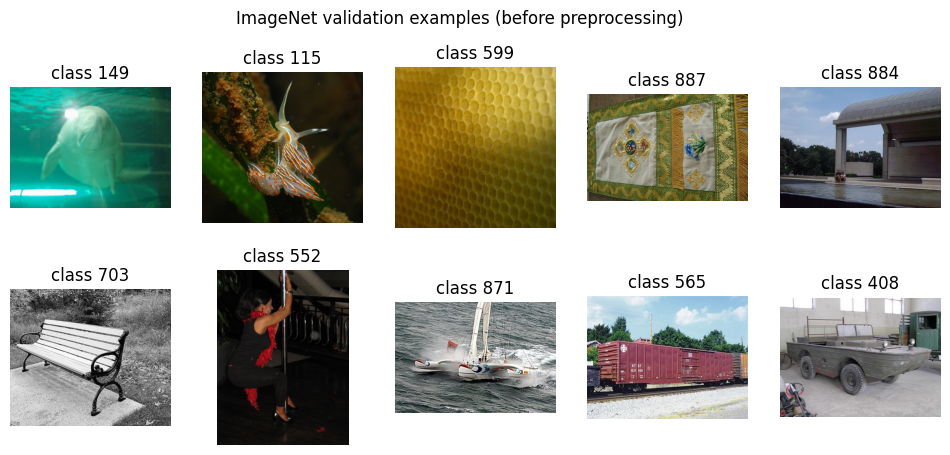

In [3]:
REPO='ILSVRC/imagenet-1k'
data_manifest_path=OUT/'imagenet_subset'/'manifest.json'
revision_path=OUT/'imagenet_subset'/'revision.json'

def load_or_download_imagenet():
    if data_manifest_path.exists():
        m=json.loads(data_manifest_path.read_text(encoding='utf-8'))
        assert m['repo']==REPO and m['split']=='validation' and len(m['images'])==1000
        assert sorted(r['label'] for r in m['images'])==list(range(1000))
        assert len({r['image_id'] for r in m['images']})==1000
        for r in m['images']:
            assert sha256_file(ROOT/r['path'])==r['sha256'], r['path']
        print('复用已校验的ImageNet子集：1000张，1000类。')
        return m
    if not get_token():
        raise RuntimeError('需要本机HF登录且接受ImageNet访问条款；不会切换为CIFAR10。')
    api=HfApi()
    if revision_path.exists():
        revision=json.loads(revision_path.read_text(encoding='utf-8'))['revision']
    else:
        revision=api.dataset_info(REPO,token=True).sha
        revision_path.write_text(json.dumps({'repo':REPO,'revision':revision}),encoding='utf-8')
    files=api.list_repo_files(REPO,repo_type='dataset',revision=revision,token=True)
    valfiles=[x for x in files if 'validation' in x.lower() and x.endswith('.parquet')]
    if not valfiles:
        raise RuntimeError('固定版本未找到validation parquet，需核对仓库结构，不自动换数据。')
    # 只验证读取权限，不将带凭据的URL写入输出。
    get_hf_file_metadata(hf_hub_url(REPO,valfiles[0],repo_type='dataset',revision=revision),token=True)
    stream=datasets.load_dataset(REPO,split='validation',revision=revision,
        streaming=True,token=True,cache_dir=str(OUT/'hf_cache'))
    stream=stream.cast_column('image',datasets.Image(decode=False))
    import io
    chosen={}; seen_hashes=set(); invalid=0; scanned=0
    started=time.monotonic()
    for row_index,row in enumerate(stream):
        scanned=row_index+1
        label=int(row['label'])
        if label in chosen: continue
        value=row['image']; raw=value.get('bytes')
        if raw is None:
            raise RuntimeError('流式记录没有图片字节，请核对数据格式。')
        digest=hashlib.sha256(raw).hexdigest()
        if digest in seen_hashes: continue
        try:
            with Image.open(io.BytesIO(raw)) as im:
                im.convert('RGB').load()
                width,height=im.size
        except (OSError,ValueError):
            invalid+=1; continue
        path=OUT/'imagenet_subset'/f'class_{label:04d}_{digest[:16]}.img'
        path.write_bytes(raw)
        chosen[label]={'image_id':f'imagenet-validation-{row_index:05d}', 'row_index':row_index,
            'label':label, 'sha256':digest,'path':str(path.relative_to(ROOT)),
            'width':width,'height':height}
        seen_hashes.add(digest)
        if len(chosen)%100==0:
            print(f'已取得{len(chosen)}/1000类，扫描{scanned}张，耗时{time.monotonic()-started:.1f}秒',flush=True)
        if len(chosen)==1000: break
    if len(chosen)!=1000:
        raise RuntimeError(f'仅取得{len(chosen)}类；不把不完整子集当成正式结果。')
    records=[chosen[c] for c in sorted(chosen)]
    np.random.default_rng(SEED).shuffle(records)
    m={'repo':REPO,'revision':revision,'split':'validation','selection':'first eligible unique bytes per class in stream order',
       'seed_for_final_order':SEED,'n':1000,'classes':1000,'scanned_rows':scanned,
       'invalid_images_skipped':invalid,'images':records}
    data_manifest_path.write_text(json.dumps(m,ensure_ascii=False,indent=2),encoding='utf-8')
    return m

data_manifest=load_or_download_imagenet()
IMAGE_IDS=[r['image_id'] for r in data_manifest['images']]
print('数据版本:',data_manifest['revision'],'划分:',data_manifest['split'])
print('每类1张，共',len(IMAGE_IDS),'张；扫描记录数:',data_manifest['scanned_rows'])
fig,axes=plt.subplots(2,5,figsize=(12,5))
for ax,r in zip(axes.flat,data_manifest['images'][:10]):
    with Image.open(ROOT/r['path']) as im: ax.imshow(im.convert('RGB'))
    ax.set_title(f"class {r['label']}"); ax.axis('off')
fig.suptitle('ImageNet validation examples (before preprocessing)')
display(fig); plt.close(fig)


## 4. 提取真实中间激活并缓存

inplace是原地修改；`detach().clone()` 立即复制卷积输出，防止后续激活改写。
每个模型每个batch只前向一次，同时取得七层。保留全部通道，不使用展示用的16个通道，也不使用探针标准化或分类概率。
缓存与数据清单、模型哈希、层名、预处理和软件版本绑定；不能只因为文件存在就盲目复用。
下面先做一个batch检查，再完成全部图片。模型逐个加载，减少16GB显存压力。


In [4]:
class ImageNetSubset(torch.utils.data.Dataset):
    def __len__(self): return len(data_manifest['images'])
    def __getitem__(self,index):
        r=data_manifest['images'][index]
        with Image.open(ROOT/r['path']) as im: x=PREPROCESS(im.convert('RGB'))
        return x,index

dataset=ImageNetSubset()
BATCH_SIZE=8
features={}; extraction_stats={}
for name,(builder,weights,layers) in SPECS.items():
    signature={'model':model_resources[name], 'data_sha256':sha256_file(data_manifest_path),
        'preprocess':preprocess_config,'representation':'raw Conv2d output before following BN/ReLU; all-channel GAP; no feature standardization',
        'torch':torch.__version__,'torchvision':torchvision.__version__,'deterministic':True,'tf32':False}
    cache=OUT/'features'/f'{name}_gap.npz'
    meta=cache.with_suffix('.json')
    if cache.exists() and meta.exists():
        saved=json.loads(meta.read_text(encoding='utf-8'))
        if saved['signature']==signature and saved['sha256']==sha256_file(cache):
            with np.load(cache,allow_pickle=False) as z:
                assert z['image_ids'].tolist()==IMAGE_IDS
                features[name]=[z[f'layer{i:02d}'].copy() for i in range(1,8)]
            extraction_stats[name]=saved['extraction']
            print('复用合格特征缓存:',name)
            continue
    model=builder(weights=weights,progress=False).eval().to(DEVICE)
    for p in model.parameters(): p.requires_grad_(False)
    modules=dict(model.named_modules())
    assert all(isinstance(modules[layer],torch.nn.Conv2d) for layer in layers)
    current={}; handles=[]; shapes={}
    def make_hook(slot):
        def hook(module,inputs,output):
            assert output.ndim==4
            shapes[slot]=list(output.shape[1:])
            current[slot]=output.detach().clone().mean(dim=(2,3)).cpu().numpy()
        return hook
    for slot,layer in enumerate(layers): handles.append(modules[layer].register_forward_hook(make_hook(slot)))
    parts=[[] for _ in layers]; indices=[]; started=time.monotonic(); batches=0
    if DEVICE.type=='cuda': torch.cuda.reset_peak_memory_stats()
    try:
        loader=torch.utils.data.DataLoader(dataset,batch_size=BATCH_SIZE,shuffle=False,
                    num_workers=0,pin_memory=DEVICE.type=='cuda')
        with torch.no_grad():
            for images,idx in loader:
                current.clear()
                output=model(images.to(DEVICE,non_blocking=True))
                assert set(current)==set(range(7))
                assert output.shape[1]==1000 and torch.isfinite(output).all().item()
                for slot in range(7): parts[slot].append(current[slot])
                indices.extend(idx.tolist()); batches+=1
                if batches==1 or batches%25==0:
                    print(name,'processed',len(indices),'/',len(dataset),flush=True)
        assert indices==list(range(len(dataset)))
        features[name]=[np.concatenate(p,axis=0).astype(np.float32,copy=False) for p in parts]
        assert all(x.shape[0]==1000 and np.isfinite(x).all() for x in features[name])
        np.savez_compressed(cache,image_ids=np.array(IMAGE_IDS),**{f'layer{i+1:02d}':x for i,x in enumerate(features[name])})
        stats={'device':str(DEVICE),'seconds':time.monotonic()-started,'batches':batches,
               'batch_size':BATCH_SIZE,'raw_shapes':{f'L{i+1:02d}':shapes[i] for i in range(7)},
               'peak_allocated_vram_gib':torch.cuda.max_memory_allocated()/1024**3 if DEVICE.type=='cuda' else None}
        extraction_stats[name]=stats
        meta.write_text(json.dumps({'signature':signature,'sha256':sha256_file(cache),'extraction':stats},indent=2),encoding='utf-8')
        print('完成:',name,'seconds:',round(stats['seconds'],1))
    finally:
        for handle in handles: handle.remove()
        del model
        current.clear(); gc.collect()
        if DEVICE.type=='cuda': torch.cuda.empty_cache()

shape_rows=[{'model':name,'slot':f'L{i+1:02d}','module':SPECS[name][2][i],
             'N':x.shape[0],'C':x.shape[1]} for name,xs in features.items() for i,x in enumerate(xs)]
display(pd.DataFrame(shape_rows))
display(pd.DataFrame(extraction_stats).T[['device','seconds','batches','peak_allocated_vram_gib']])


复用合格特征缓存: vgg16
复用合格特征缓存: resnet50
复用合格特征缓存: mobilenet_v2


,model,slot,module,N,C
0,vgg16,L01,features.0,1000,64
1,vgg16,L02,features.5,1000,128
2,vgg16,L03,features.10,1000,256
3,vgg16,L04,features.14,1000,256
4,vgg16,L05,features.19,1000,512
5,vgg16,L06,features.24,1000,512
6,vgg16,L07,features.28,1000,512
7,resnet50,L01,conv1,1000,64
8,resnet50,L02,layer1.2.conv2,1000,64
9,resnet50,L03,layer2.2.conv1,1000,128


,device,seconds,batches,peak_allocated_vram_gib
vgg16,cuda,10.547,125,1.082683
resnet50,cuda,5.078,125,0.209939
mobilenet_v2,cuda,4.593,125,0.127761


## 5. Linear CKA公式与数值自检

中心化：每个特征列减去其在所有图片上的平均值，得到Xc、Yc。

\[
\mathrm{CKA}(X,Y)=\frac{\|X_c^T Y_c\|_F^2}{\|X_c^T X_c\|_F\,\|Y_c^T Y_c\|_F}.
\]

T是转置；F范数是矩阵元素平方和开平方。
也可比较样本内积矩阵（Gram矩阵）`K=Xc@Xc.T`、`L=Yc@Yc.T`，两种实现等价。
普通、非去偏Linear CKA在非退化时介于0和1；不是准确率，没有通用“0.8即好”的标准。
只有一张图时中心化全零；两张图在非退化时恒为1，因此本研究使用多图片。
逐通道标准化会改变表示，不能与CKA中心化混为一谈。


In [5]:
def center_features(x):
    x=np.asarray(x,dtype=np.float64)
    if x.ndim!=2 or x.shape[0]<3 or not np.isfinite(x).all():
        raise ValueError('需要至少3行的有限二维矩阵；正式实验使用1000张。')
    return x-x.mean(axis=0,keepdims=True)

def normalized_gram(x):
    x=center_features(x)
    g=x@x.T
    norm=np.linalg.norm(g,'fro')
    if norm==0 or not np.isfinite(norm): raise ValueError('零变化表示或无效范数，CKA未定义。')
    return g/norm

def linear_cka(x,y):
    if len(x)!=len(y): raise ValueError('样本行数不同。')
    return float(np.sum(normalized_gram(x)*normalized_gram(y)))

def feature_space_cka(x,y):
    x,y=center_features(x),center_features(y)
    denom=np.linalg.norm(x.T@x,'fro')*np.linalg.norm(y.T@y,'fro')
    if denom==0: raise ValueError('CKA未定义。')
    return float(np.linalg.norm(x.T@y,'fro')**2/denom)

rng=np.random.default_rng(SEED)
x,y=rng.normal(size=(48,12)),rng.normal(size=(48,9))
p=rng.permutation(48); base=linear_cka(x,y)
checks={'self':np.isclose(linear_cka(x,x),1),
        'symmetry':np.isclose(base,linear_cka(y,x)),
        'joint_permutation':np.isclose(base,linear_cka(x[p],y[p])),
        'translation':np.isclose(base,linear_cka(x+np.arange(12),y+2)),
        'uniform_scaling':np.isclose(base,linear_cka(-3*x,2*y)),
        'two_equivalent_implementations':np.isclose(base,feature_space_cka(x,y),atol=1e-10)}
for label,a,b in [('constant',np.ones((48,3)),y),('two_samples',x[:2],y[:2]),
                  ('different_N',x,y[:-1]),('nonfinite',np.full((48,3),np.nan),y)]:
    try: linear_cka(a,b); checks['reject_'+label]=False
    except ValueError: checks['reject_'+label]=True
assert all(checks.values()),checks
display(pd.Series(checks,name='passed').to_frame())


,passed
self,True
symmetry,True
joint_permutation,True
translation,True
uniform_scaling,True
two_equivalent_implementations,True
reject_constant,True
reject_two_samples,True
reject_different_N,True
reject_nonfinite,True


## 6. 正式结果：三个模型配对，每对49个层组合

每个模型七层，三对模型共 `3×7×7=147` 个分数。
不只看同槽位，避免预先假设不同架构的层语义对应。矩阵图是CKA数值的展示，非Grad-CAM空间归因。


9个真实浅／中／深组合经独立特征空间公式复算通过；最大误差： 1.887379141862766e-15


model_a,slot_a,module_a,model_b,slot_b,module_b,cka,n,dataset,representation,estimator
vgg16,L01,features.0,resnet50,L01,conv1,0.995739,1000,ImageNet validation,raw_conv_GAP,ordinary_linear_CKA
vgg16,L01,features.0,resnet50,L02,layer1.2.conv2,0.092205,1000,ImageNet validation,raw_conv_GAP,ordinary_linear_CKA
vgg16,L01,features.0,resnet50,L03,layer2.2.conv1,0.078737,1000,ImageNet validation,raw_conv_GAP,ordinary_linear_CKA
vgg16,L01,features.0,resnet50,L04,layer3.0.conv3,0.069648,1000,ImageNet validation,raw_conv_GAP,ordinary_linear_CKA
vgg16,L01,features.0,resnet50,L05,layer3.3.conv2,0.054160,1000,ImageNet validation,raw_conv_GAP,ordinary_linear_CKA
vgg16,L01,features.0,resnet50,L06,layer4.0.conv1,0.157972,1000,ImageNet validation,raw_conv_GAP,ordinary_linear_CKA
vgg16,L01,features.0,resnet50,L07,layer4.2.conv3,0.062742,1000,ImageNet validation,raw_conv_GAP,ordinary_linear_CKA
vgg16,L02,features.5,resnet50,L01,conv1,0.104443,1000,ImageNet validation,raw_conv_GAP,ordinary_linear_CKA
vgg16,L02,features.5,resnet50,L02,layer1.2.conv2,0.478155,1000,ImageNet validation,raw_conv_GAP,ordinary_linear_CKA
vgg16,L02,features.5,resnet50,L03,layer2.2.conv1,0.665702,1000,ImageNet validation,raw_conv_GAP,ordinary_linear_CKA


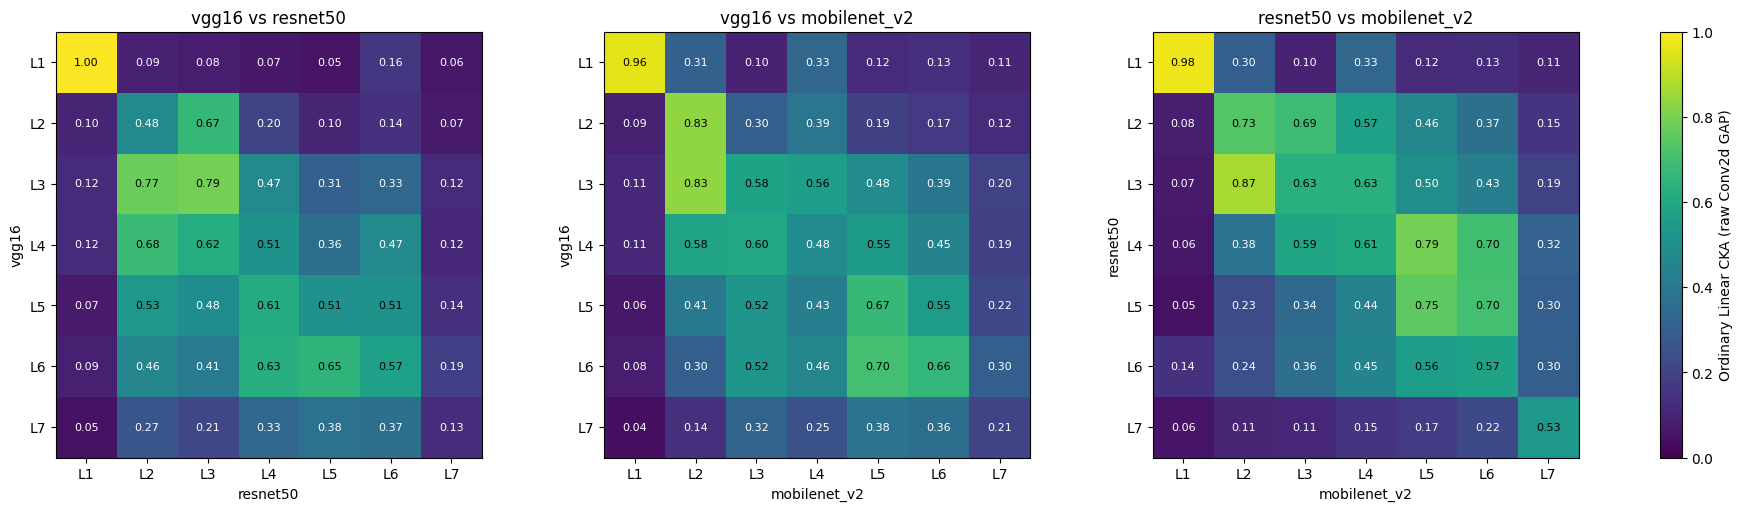

In [6]:
names=list(SPECS)
PAIRS=[(names[0],names[1]),(names[0],names[2]),(names[1],names[2])]
grams={name:np.stack([normalized_gram(x) for x in features[name]]) for name in names}
flat={name:g.reshape(7,-1) for name,g in grams.items()}
matrices={(a,b):flat[a]@flat[b].T for a,b in PAIRS}
assert all(np.isfinite(m).all() and m.min()>=-1e-9 and m.max()<=1+1e-9 for m in matrices.values())
audit_rows=[]
for (a,b),m in matrices.items():
    for i in [0,3,6]:
        independent=feature_space_cka(features[a][i],features[b][i])
        error=abs(independent-m[i,i])
        assert error<1e-10
        audit_rows.append({'model_a':a,'model_b':b,'slot':i+1,
                           'gram_cka':float(m[i,i]),'feature_space_cka':independent,'absolute_error':error})
numeric_audit=pd.DataFrame(audit_rows)
numeric_audit.to_csv(OUT/'results'/'cka_numeric_audit.csv',index=False)
print('9个真实浅／中／深组合经独立特征空间公式复算通过；最大误差：',numeric_audit['absolute_error'].max())
rows=[]
for (a,b),m in matrices.items():
    for i in range(7):
        for j in range(7):
            rows.append({'model_a':a,'slot_a':f'L{i+1:02d}','module_a':SPECS[a][2][i],
                'model_b':b,'slot_b':f'L{j+1:02d}','module_b':SPECS[b][2][j],
                'cka':float(m[i,j]),'n':1000,'dataset':'ImageNet validation',
                'representation':'raw_conv_GAP','estimator':'ordinary_linear_CKA'})
results=pd.DataFrame(rows)
assert len(results)==147
results.to_csv(OUT/'results'/'cka_main.csv',index=False)
display(HTML('<details open><summary>完整147个CKA数值（可折叠）</summary>'+results.to_html(index=False,float_format=lambda x:f'{x:.6f}')+'</details>'))
fig,axes=plt.subplots(1,3,figsize=(18,5),constrained_layout=True)
for ax,((a,b),m) in zip(axes,matrices.items()):
    im=ax.imshow(m,vmin=0,vmax=1,cmap='viridis')
    ax.set_title(f'{a} vs {b}')
    ax.set_xlabel(b); ax.set_ylabel(a)
    ax.set_xticks(range(7),[f'L{i}' for i in range(1,8)])
    ax.set_yticks(range(7),[f'L{i}' for i in range(1,8)])
    for i in range(7):
        for j in range(7): ax.text(j,i,f'{m[i,j]:.2f}',ha='center',va='center',fontsize=8,
                                color='white' if m[i,j]<0.5 else 'black')
fig.colorbar(im,ax=axes,label='Ordinary Linear CKA (raw Conv2d GAP)')
fig.savefig(OUT/'figures'/'cka_matrices.png',dpi=180)
display(fig); plt.close(fig)


## 7. 可靠性：样本规模和错配对照

普通CKA可能受样本量及维度影响。只打乱一侧图片ID，使正确配对关系被破坏，作为诊断对照，不能预设它一定接近0。
重复10次错配，保存每个层组合的结果；不称为统计显著性检验。
250、500、1000张是同一主集的嵌套子集；由于每类仅一张，规模变化也改变类别覆盖，不能将差异全归因于N。
从全样本Gram截取子矩阵后必须重新中心化；直接截取计算会错误。


错配对照完成 1 /10


错配对照完成

 2 /10


错配对照完成 3 /10


错配对照完成

...

 7 /10


错配对照完成 8 /10


错配对照完成 9 /10


错配对照完成 10 /10


,pair,n,same_slot_mean,max_absolute_change_from_1000
0,vgg16 / resnet50,250,0.584817,6.192301e-02
1,vgg16 / resnet50,500,0.577771,3.697362e-02
2,vgg16 / resnet50,1000,0.568981,4.440892e-16
3,vgg16 / mobilenet_v2,250,0.637989,5.410735e-02
4,vgg16 / mobilenet_v2,500,0.640008,3.284700e-02
5,vgg16 / mobilenet_v2,1000,0.627196,3.330669e-16
6,resnet50 / mobilenet_v2,250,0.702231,1.205989e-01
7,resnet50 / mobilenet_v2,500,0.691325,4.835166e-02
8,resnet50 / mobilenet_v2,1000,0.687575,2.220446e-16


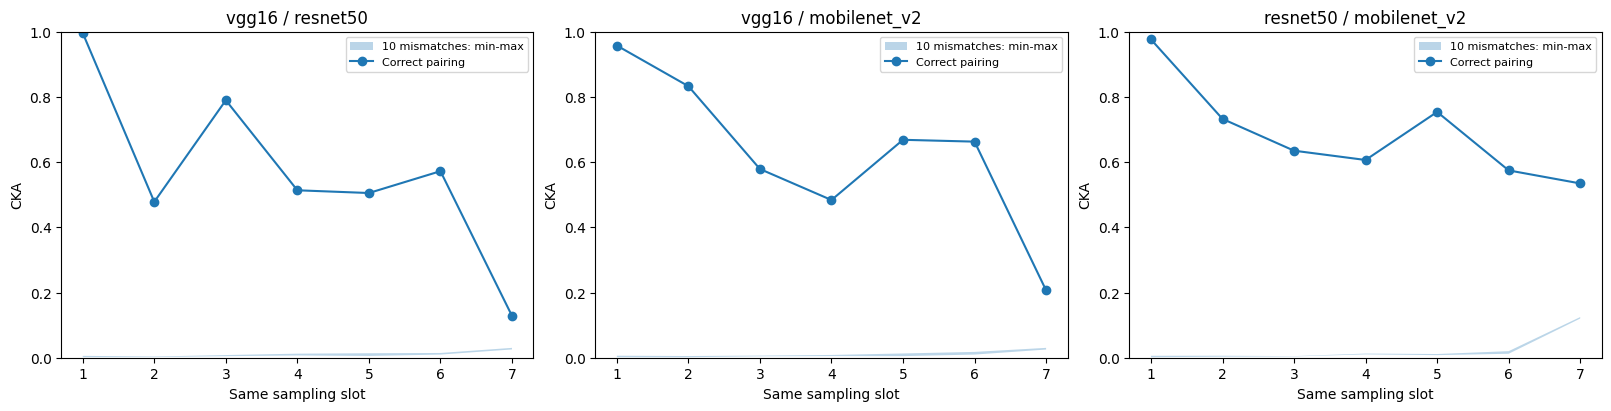

In [7]:
def subset_gram(g,idx):
    s=g[np.ix_(idx,idx)].copy()
    s=s-s.mean(axis=0,keepdims=True)-s.mean(axis=1,keepdims=True)+s.mean()
    norm=np.linalg.norm(s,'fro')
    if norm==0: raise ValueError('子集表示退化。')
    return s/norm

check_rows=[]; stability={}; shuffle_matrices={pair:[] for pair in PAIRS}
for n in [250,500,1000]:
    idx=np.arange(n)
    fs={name:np.stack([subset_gram(g,idx).ravel() for g in grams[name]]) for name in names}
    for a,b in PAIRS:
        m=fs[a]@fs[b].T
        stability[(a,b,n)]=m
        for i in range(7):
            for j in range(7): check_rows.append({'kind':'sample_size','model_a':a,'model_b':b,
                'slot_a':i+1,'slot_b':j+1,'n':n,'repeat':0,'seed':SEED,'cka':float(m[i,j])})
    del fs
# 验证子集Gram重中心化与直接重算一致。
assert np.allclose(subset_gram(grams[names[0]][0],np.arange(40)),
                   normalized_gram(features[names[0]][0][:40]),atol=1e-10)
for repeat in range(10):
    seed=SEED+1000+repeat
    permutation=np.random.default_rng(seed).permutation(1000)
    for a,b in PAIRS:
        shuffled=grams[b][:,permutation,:][:,:,permutation].reshape(7,-1)
        m=flat[a]@shuffled.T
        shuffle_matrices[(a,b)].append(m)
        for i in range(7):
            for j in range(7): check_rows.append({'kind':'mismatched_rows','model_a':a,'model_b':b,
                'slot_a':i+1,'slot_b':j+1,'n':1000,'repeat':repeat+1,'seed':seed,'cka':float(m[i,j])})
    print('错配对照完成',repeat+1,'/10',flush=True)
    del shuffled
check_df=pd.DataFrame(check_rows)
check_df.to_csv(OUT/'results'/'cka_checks.csv',index=False)
diagnostic=[]
for (a,b),m in matrices.items():
    sh=np.stack(shuffle_matrices[(a,b)])
    for n in [250,500,1000]:
        diagnostic.append({'pair':f'{a} / {b}','n':n,
            'same_slot_mean':float(np.diag(stability[(a,b,n)]).mean()),
            'max_absolute_change_from_1000':float(np.abs(stability[(a,b,n)]-m).max())})
display(pd.DataFrame(diagnostic))
fig,axes=plt.subplots(1,3,figsize=(16,4),constrained_layout=True)
for ax,((a,b),m) in zip(axes,matrices.items()):
    sh=np.stack(shuffle_matrices[(a,b)])
    lo=np.diag(sh.min(axis=0)); hi=np.diag(sh.max(axis=0))
    ax.fill_between(range(1,8),lo,hi,alpha=.3,label='10 mismatches: min-max')
    ax.plot(range(1,8),np.diag(m),'o-',label='Correct pairing')
    ax.set(title=f'{a} / {b}',xlabel='Same sampling slot',ylabel='CKA',ylim=(0,1))
    ax.legend(fontsize=8)
fig.savefig(OUT/'figures'/'cka_mismatch_controls.png',dpi=180)
display(fig); plt.close(fig)


## 8. 根据真实结果生成的解释

下面的文字由上面实际数值生成，讨论浅／中／深的**采样组**与跨槽位最大值，不宣称它们具有相同感受野或语义。
最大值是在49个组合中事后找到的描述性结果，不是预先指定的统计检验。


In [8]:
lines=['# ImageNet Linear CKA 实际结果与解释',
       f"数据：{REPO}，版本 `{data_manifest['revision']}`，validation，1000类各1张。",
       '选图：固定流式顺序中每类第一张可解码、字节唯一的图片；非均匀随机样本。',
       '模型：三个IMAGENET1K_V1；表示：七个原始卷积输出的全部通道GAP；方法：普通中心化Linear CKA。']
for (a,b),m in matrices.items():
    i,j=np.unravel_index(np.argmax(m),m.shape)
    diagonal=np.diag(m)
    groups=[float(diagonal[:2].mean()),float(diagonal[2:5].mean()),float(diagonal[5:].mean())]
    sh=np.stack(shuffle_matrices[(a,b)])
    gaps=diagonal-np.diag(sh.mean(axis=0))
    count=int(np.sum(diagonal>np.diag(sh.max(axis=0))))
    delta250=float(np.abs(stability[(a,b,250)]-m).max())
    delta500=float(np.abs(stability[(a,b,500)]-m).max())
    trend='较高' if groups[0]>groups[2] else '较低' if groups[0]<groups[2] else '相同'
    best_columns=m.argmax(axis=1)
    gains=m[np.arange(7),best_columns]-diagonal
    example=int(np.argmax(gains)); example_col=int(best_columns[example])
    increases=int(np.sum(np.diff(diagonal)>0))
    lines.extend([f'\n## {a} 与 {b}',
        f'最高组合：{SPECS[a][2][i]}（L{i+1:02d}）与 {SPECS[b][2][j]}（L{j+1:02d}），CKA={m[i,j]:.4f}。',
        f'同槽位浅层L01–L02、中层L03–L05、深层L06–L07的均值依次为 {groups[0]:.4f}、{groups[1]:.4f}、{groups[2]:.4f}；浅层组的均值{trend}。',
        f'最后槽位L07对L07为 {m[6,6]:.4f}。同槽位曲线有{increases}处向上变化，不能把组均值趋势说成每层都下降。',
        f'跨槽位例子：{a} L{example+1:02d} 与 {b} L{example_col+1:02d} 的CKA为 {m[example,example_col]:.4f}，而与 {b} 同槽位L{example+1:02d}的分数是 {diagonal[example]:.4f}。这说明直接按槽位比较会漏掉部分关系，并非证明语义层已严格对齐。',
        f'相对于1000张，250／500张矩阵的最大绝对变化为 {delta250:.4f}／{delta500:.4f}。规模与类别覆盖同时变化。',
        f'7个同槽位中有{count}个正确配对值高于10次错配对照的最大值；相对错配均值的差范围为 {gaps.min():.4f} 至 {gaps.max():.4f}。该对照不等于显著性证明。'])
lines.extend(['\n## 初学者怎样理解这些结果？',
 'CKA=0.9957这样的值表示特定表示的关系结构很接近，不是99.57%分类正确，也不是99.57%的神经元相同。',
 '三对模型均在L01对L01达到本矩阵最高值，且浅层采样组均值高于深层组；同时中间层有上升和跨槽位高值，因此结论应是所选采样组呈现总体差异，而非一条普遍单调规律。',
 '第一层原始卷积是近似线性变换，经过GAP后空间排列被平均，表示可能主要反映全局颜色／亮度统计；这是对高L01分数的一种解释假设，本实验没有另做颜色消融来验证，不能把高分解释为所有边缘检测器相同。',
 'ResNet50与MobileNetV2在L07的相似程度高于涉及VGG16的两对L07结果；这里只能讨论该原始卷积GAP定义下的相似度，不能据此说MobileNetV2更准确或更优。',
 f'9个真实浅／中／深层组合通过另一种等价的特征空间公式复算，最大误差为 {numeric_audit["absolute_error"].max():.2e}。这验证保存特征上的CKA算术，不是独立重放全部CNN前向。'])
lines.extend(['\n## 适用范围与限制',
 '1. 只描述固定ImageNet验证子集的GAP表示关系；不代表完整空间特征等价。',
 '2. 每类仅1张，不能估计类内变化。顺序配额选样和完全重复字节过滤不等于随机抽样或近重复清理。',
 '3. 槽位基于卷积顺序；跨架构的操作角色、通道数和感受野不同。ResNet卷积点在BN及残差相加之前。',
 '4. 普通CKA可能受维度、样本数和主导变化影响。错配也高或规模变化大时，应扩大数据并补充独立抽样／去偏分析，而不是宣布结论稳健。',
 '5. 高相似度不是准确率、因果依据、公平性或模型质量；低相似度不等于没有有效特征。',
 '6. 不能仅用本实验断言浅层普遍相似或深层普遍不同，也不能用CKA给模型排名谁最好。',
 '\n## 团队衔接',
 '本模块提供表示相似度的定量证据，与搭档的通道合成偏好、猫狗个案归因及线性探针互补。',
 '建议从真实数值中选一个最易解释的发现作为meme／视频素材，不把未验证的趋势写进文案。'])
summary='\n\n'.join(lines)
display(Markdown(summary))
(OUT/'summary.md').write_text(summary,encoding='utf-8')


# ImageNet Linear CKA 实际结果与解释

数据：ILSVRC/imagenet-1k，版本 `49e2ee26f3810fb5a7536bbf732a7b07389a47b5`，validation，1000类各1张。

选图：固定流式顺序中每类第一张可解码、字节唯一的图片；非均匀随机样本。

模型：三个IMAGENET1K_V1；表示：七个原始卷积输出的全部通道GAP；方法：普通中心化Linear CKA。


## vgg16 与 resnet50

最高组合：features.0（L01）与 conv1（L01），CKA=0.9957。

同槽位浅层L01–L02、中层L03–L05、深层L06–L07的均值依次为 0.7369、0.6028、0.3503；浅层组的均值较高。

最后槽位L07对L07为 0.1285。同槽位曲线有2处向上变化，不能把组均值趋势说成每层都下降。

跨槽位例子：vgg16 L07 与 resnet50 L05 的CKA为 0.3781，而与 resnet50 同槽位L07的分数是 0.1285。这说明直接按槽位比较会漏掉部分关系，并非证明语义层已严格对齐。

相对于1000张，250／500张矩阵的最大绝对变化为 0.0619／0.0370。规模与类别覆盖同时变化。

7个同槽位中有7个正确配对值高于10次错配对照的最大值；相对错配均值的差范围为 0.1006 至 0.9923。该对照不等于显著性证明。


## vgg16 与 mobilenet_v2

最高组合：features.0（L01）与 features.0.0（L01），CKA=0.9574。

同槽位浅层L01–L02、中层L03–L05、深层L06–L07的均值依次为 0.8951、0.5769、0.4347；浅层组的均值较高。

最后槽位L07对L07为 0.2067。同槽位曲线有1处向上变化，不能把组均值趋势说成每层都下降。

跨槽位例子：vgg16 L03 与 mobilenet_v2 L02 的CKA为 0.8321，而与 mobilenet_v2 同槽位L03的分数是 0.5787。这说明直接按槽位比较会漏掉部分关系，并非证明语义层已严格对齐。

相对于1000张，250／500张矩阵的最大绝对变化为 0.0541／0.0328。规模与类别覆盖同时变化。

7个同槽位中有7个正确配对值高于10次错配对照的最大值；相对错配均值的差范围为 0.1793 至 0.9539。该对照不等于显著性证明。


## resnet50 与 mobilenet_v2

最高组合：conv1（L01）与 features.0.0（L01），CKA=0.9763。

同槽位浅层L01–L02、中层L03–L05、深层L06–L07的均值依次为 0.8544、0.6651、0.5545；浅层组的均值较高。

最后槽位L07对L07为 0.5346。同槽位曲线有1处向上变化，不能把组均值趋势说成每层都下降。

跨槽位例子：resnet50 L03 与 mobilenet_v2 L02 的CKA为 0.8679，而与 mobilenet_v2 同槽位L03的分数是 0.6350。这说明直接按槽位比较会漏掉部分关系，并非证明语义层已严格对齐。

相对于1000张，250／500张矩阵的最大绝对变化为 0.1206／0.0484。规模与类别覆盖同时变化。

7个同槽位中有7个正确配对值高于10次错配对照的最大值；相对错配均值的差范围为 0.4123 至 0.9728。该对照不等于显著性证明。


## 初学者怎样理解这些结果？

CKA=0.9957这样的值表示特定表示的关系结构很接近，不是99.57%分类正确，也不是99.57%的神经元相同。

三对模型均在L01对L01达到本矩阵最高值，且浅层采样组均值高于深层组；同时中间层有上升和跨槽位高值，因此结论应是所选采样组呈现总体差异，而非一条普遍单调规律。

第一层原始卷积是近似线性变换，经过GAP后空间排列被平均，表示可能主要反映全局颜色／亮度统计；这是对高L01分数的一种解释假设，本实验没有另做颜色消融来验证，不能把高分解释为所有边缘检测器相同。

ResNet50与MobileNetV2在L07的相似程度高于涉及VGG16的两对L07结果；这里只能讨论该原始卷积GAP定义下的相似度，不能据此说MobileNetV2更准确或更优。

9个真实浅／中／深层组合通过另一种等价的特征空间公式复算，最大误差为 1.89e-15。这验证保存特征上的CKA算术，不是独立重放全部CNN前向。


## 适用范围与限制

1. 只描述固定ImageNet验证子集的GAP表示关系；不代表完整空间特征等价。

2. 每类仅1张，不能估计类内变化。顺序配额选样和完全重复字节过滤不等于随机抽样或近重复清理。

3. 槽位基于卷积顺序；跨架构的操作角色、通道数和感受野不同。ResNet卷积点在BN及残差相加之前。

4. 普通CKA可能受维度、样本数和主导变化影响。错配也高或规模变化大时，应扩大数据并补充独立抽样／去偏分析，而不是宣布结论稳健。

5. 高相似度不是准确率、因果依据、公平性或模型质量；低相似度不等于没有有效特征。

6. 不能仅用本实验断言浅层普遍相似或深层普遍不同，也不能用CKA给模型排名谁最好。


## 团队衔接

本模块提供表示相似度的定量证据，与搭档的通道合成偏好、猫狗个案归因及线性探针互补。

建议从真实数值中选一个最易解释的发现作为meme／视频素材，不把未验证的趋势写进文案。

2362

In [9]:
config={'complete':True,'environment':environment,'seed':SEED,'batch_size':BATCH_SIZE,
    'dataset_manifest_sha256':sha256_file(data_manifest_path),'dataset':{
        k:v for k,v in data_manifest.items() if k!='images'},
    'image_ids':IMAGE_IDS,'models':model_resources,'preprocess':preprocess_config,
    'representation':'all-channel GAP of raw Conv2d output before subsequent BN/ReLU; no probe standardization',
    'estimator':'ordinary centered linear CKA','main_scores':len(results),
    'formula_checks':{k:bool(v) for k,v in checks.items()},'extraction':extraction_stats,
    'real_feature_numeric_audit':{'combinations':len(numeric_audit),'max_absolute_error':float(numeric_audit['absolute_error'].max())},
    'controls':{'sample_sizes':[250,500,1000],'mismatch_repetitions':10},
        'result_sha256':sha256_file(OUT/'results'/'cka_main.csv'),
    'controls_sha256':sha256_file(OUT/'results'/'cka_checks.csv')}
(OUT/'experiment_config.json').write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8')
print('完成：21个层表示，147个主分数；公式检查通过；规模与错配对照完成。')
print('附属结果目录：',OUT)
print('重新运行优先校验缓存；所有结论均由真实结果生成。')


完成：21个层表示，147个主分数；公式检查通过；规模与错配对照完成。
附属结果目录： C:\Users\Seinz\Desktop\xai-a2\cka_study
重新运行优先校验缓存；所有结论均由真实结果生成。


## 9. 新增研究问题：Grad-CAM 指出的区域经得起扰动检查吗？

**CKA比较模型表示，Insertion/Deletion评估解释图；两者回答不同问题。**
本节沿用前述ImageNet子集、预处理及七个原始卷积取样点。在固定顺序的前100张图（100个不同类别）上，
对三个模型各七层的Grad-CAM进行评估，共2,100组图片—模型—层组合，另加每模型每图一个随机排序对照。
不按预测是否正确筛选图片，不挑选视觉效果最好的例子。100张是计算预算下的探索性样本，不代表完整ImageNet。

### Grad-CAM、目标类别和排序

对每张图，固定该模型原始完整输入的Top-1类别`t`，对其 **logit** 求梯度；不同模型的`t`可能不同。
每通道的梯度空间均值作为权重，与原始激活加权求和后整体ReLU，再双线性放大至224×224。
这会把类别相关的空间响应转换为像素排序；它不是把CKA分数当成热力图。
七层、Insertion、Deletion和随机对照始终追踪同一个`t`，不会在每次遮挡后重新选Top-1。

先把所有ReLU/ReLU6设为非inplace，确认前向结果与原模型一致，再取梯度，避免原地修改破坏取样值。
卷积点仍在后续BN/ReLU之前。CUDA反向在`deterministic warn_only=True`下执行：固定种子与确定性卷积设置，
但不承诺全部梯度逐bit复现。缓存及其哈希用于复算，不能把复算缓存当成独立重放反向。

### Insertion／Deletion／AUC 是什么？

- **Insertion（插入）：**从基线图开始，按Grad-CAM由高到低逐步恢复原图像素；记录`t`的softmax概率。好的排序通常使分数较快恢复。
- **Deletion（删除）：**从原图开始，按同一排序逐步把像素替换成基线值；好的排序通常使分数较快降低。
- **基线（baseline）：**本节统一使用ImageNet均值RGB `(0.485,0.456,0.406)` 的纯色图，也就是归一化张量中的全零；**不是黑色图**。
- **AUC（曲线下面积）：**横轴是已插入／删除像素比例，纵轴是固定目标概率；包含0%和100%，20个区间、21个采样点，用梯形积分。
  **Insertion AUC越高越好，Deletion AUC越低越好。** Lecture6a使用的是另一种概率差定义，不能沿用其所有“高／低更好”方向。
- **随机对照：**每张图用固定种子的像素随机排序，同一排序复用于三个模型。像素同分时也用该随机优先级打破平局；全零CAM的排序因此等于随机对照。
- **配对改进：**Insertion改进=`CAM AUC−随机AUC`；Deletion改进=`随机AUC−CAM AUC`，两者正值均表示优于该随机排序。
  以图片为单位进行1,000次配对bootstrap，报告均值及95%百分位区间；它不是总体因果证明，也未做多重比较校正。

本节使用同一种均值基线，便于控制变量，并非复刻RISE默认的所有设置；基线改变、遮挡造成分布外图像、步长和解释分辨率都可能影响排名。
“AUC更好”仅说明在此扰动协议下更有效，不证明完整因果解释，也不用于跨不同目标类别给模型准确率排名。
参考：[Grad-CAM](https://arxiv.org/abs/1610.02391)、[RISE及Insertion/Deletion](https://arxiv.org/abs/1806.07421)。


In [10]:
import warnings
import torch.nn.functional as F

ID_DIR=OUT/'insertion_deletion'
ID_DIR.mkdir(exist_ok=True)
ID_N=100
ID_STEPS=20
ID_BATCH=32
ID_REPEATS=1000
ID_RECORDS=data_manifest['images'][:ID_N]
ID_IMAGE_IDS=[r['image_id'] for r in ID_RECORDS]
assert len(ID_IMAGE_IDS)==len(set(ID_IMAGE_IDS))==ID_N
assert len({r['label'] for r in ID_RECORDS})==ID_N
PIXELS=224*224
ID_COUNTS=np.rint(np.linspace(0,PIXELS,ID_STEPS+1)).astype(np.int64)
ID_FRACTIONS=ID_COUNTS/PIXELS
assert ID_COUNTS[0]==0 and ID_COUNTS[-1]==PIXELS and np.all(np.diff(ID_COUNTS)>0)
ID_METHODS=[f'L{i:02d}' for i in range(1,8)]+['random']
ID_PROTOCOL={'n':ID_N,'selection':'first 100 records in the fixed seeded ImageNet subset order; no correctness filter',
    'image_ids':ID_IMAGE_IDS,'data_manifest_sha256':sha256_file(data_manifest_path),
    'target':'original full-input model Top-1; fixed across layers, perturbations and controls',
    'attribution':'Grad-CAM on original target logit; channel-mean gradient; weighted sum then ReLU',
    'map_resize':'bilinear 224x224 align_corners=False; nonnegative per-map maximum normalization',
    'baseline':'zero normalized tensor = ImageNet RGB mean, not black',
    'counts':ID_COUNTS.tolist(),'fractions':ID_FRACTIONS.tolist(),
    'score':'softmax probability of the fixed original target; not probability difference',
    'auc':'trapezoidal integral over actual pixel fractions; insertion higher, deletion lower',
    'tie_break':'per-image seeded random priority; all-zero map exactly equals random ordering',
    'seed':SEED,'random_order_seed_offset':20000,
    'cam_backward':'CUDA deterministic warn_only=True; bitwise reproducibility not guaranteed',
    'bootstrap_replicates':ID_REPEATS,'bootstrap_unit':'paired image',
    'torch':torch.__version__,'torchvision':torchvision.__version__,'preprocess':preprocess_config}

def random_priority(image_index):
    return np.random.default_rng(SEED+20000+image_index).permutation(PIXELS)

def ranked_pixels(cam,image_index):
    values=np.asarray(cam,dtype=np.float32).reshape(-1)
    assert values.size==PIXELS and np.isfinite(values).all()
    return np.lexsort((random_priority(image_index),-values))

def pixel_masks(order):
    assert np.array_equal(np.sort(order),np.arange(PIXELS))
    ranks=np.empty(PIXELS,dtype=np.int64)
    ranks[order]=np.arange(PIXELS)
    masks=ranks[None,:]<ID_COUNTS[:,None]
    assert np.array_equal(masks.sum(1),ID_COUNTS)
    return torch.from_numpy(masks.reshape(-1,1,224,224)).to(DEVICE)

def auc_probability(curve):
    return np.trapezoid(np.asarray(curve,dtype=np.float64),x=ID_FRACTIONS,axis=-1)

# Endpoint, ranking, and integration checks verify the perturbation protocol.
test_order=ranked_pixels(np.zeros((224,224),np.float32),0)
assert np.array_equal(test_order,np.argsort(random_priority(0)))
test_mask=pixel_masks(test_order)
assert not test_mask[0].any().item() and test_mask[-1].all().item()
assert np.isclose(auc_probability(np.ones(21)),1)
assert np.isclose(auc_probability(ID_FRACTIONS),0.5)
assert np.isclose(auc_probability(1-ID_FRACTIONS),0.5)
del test_mask
print('Protocol checks passed: masks, endpoints, constant/linear AUC, zero-CAM random equivalence.')
display(pd.DataFrame([{'quantity':'I/D images','value':ID_N},
    {'quantity':'Grad-CAM image-model-layer combinations','value':ID_N*3*7},
    {'quantity':'Random image-model controls','value':ID_N*3},
    {'quantity':'Curve samples including endpoints','value':ID_STEPS+1}]))


Protocol checks passed: masks, endpoints, constant/linear AUC, zero-CAM random equivalence.


,quantity,value
0,I/D images,100
1,Grad-CAM image-model-layer combinations,2100
2,Random image-model controls,300
3,Curve samples including endpoints,21


In [11]:
id_data={}
for name,(builder,weights,layers) in SPECS.items():
    signature={'protocol':ID_PROTOCOL,'model':model_resources[name]}
    cache=ID_DIR/f'{name}_id.npz'
    meta=cache.with_suffix('.json')
    if cache.exists() and meta.exists():
        saved=json.loads(meta.read_text(encoding='utf-8'))
        if saved['signature']==signature and saved['sha256']==sha256_file(cache):
            with np.load(cache,allow_pickle=False) as f: arrays={k:f[k].copy() for k in f.files}
            assert arrays['image_ids'].tolist()==ID_IMAGE_IDS
            assert arrays['curves'].shape==(ID_N,8,2,ID_STEPS+1)
            id_data[name]=arrays
            print('Verified I/D cache:',name)
            continue
    started=time.monotonic()
    model=builder(weights=weights,progress=False).eval().to(DEVICE)
    for p in model.parameters(): p.requires_grad_(False)
    first=dataset[0][0].unsqueeze(0).to(DEVICE)
    with torch.no_grad(): original_output=model(first)
    for module in model.modules():
        if isinstance(module,(torch.nn.ReLU,torch.nn.ReLU6)): module.inplace=False
    with torch.no_grad(): adjusted_output=model(first)
    equivalence_error=float((original_output-adjusted_output).abs().max().item())
    assert torch.allclose(original_output,adjusted_output,atol=1e-6,rtol=1e-6)
    del original_output,adjusted_output,first
    cams=np.empty((ID_N,7,224,224),dtype=np.float32)
    targets=np.empty(ID_N,dtype=np.int64)
    original_prob=np.empty(ID_N,dtype=np.float64)
    warnings_seen=set()
    modules=dict(model.named_modules())
    grad_started=time.monotonic()
    old_deterministic=torch.are_deterministic_algorithms_enabled()
    old_warn_only=torch.is_deterministic_algorithms_warn_only_enabled()
    torch.use_deterministic_algorithms(True,warn_only=True)
    try:
        for image_index in range(ID_N):
            x=dataset[image_index][0].unsqueeze(0).to(DEVICE).requires_grad_(True)
            activations={}; snapshots={}; handles=[]
            def capture(slot):
                def hook(module,inputs,output):
                    activations[slot]=output
                    snapshots[slot]=output.detach().clone()
                return hook
            for slot,layer in enumerate(layers):
                handles.append(modules[layer].register_forward_hook(capture(slot)))
            try:
                with warnings.catch_warnings(record=True) as captured:
                    warnings.simplefilter('always')
                    logits=model(x)
                    target=int(logits.argmax(1).item())
                    gradients=torch.autograd.grad(logits[0,target],[activations[i] for i in range(7)])
                for w in captured: warnings_seen.add(str(w.message).split(' (')[0][:300])
                targets[image_index]=target
                original_prob[image_index]=logits.softmax(1)[0,target].item()
                for slot,(activation,gradient) in enumerate(zip([snapshots[i] for i in range(7)],gradients)):
                    raw=F.relu((gradient.mean((2,3),keepdim=True)*activation).sum(1,keepdim=True))
                    scaled=F.interpolate(raw,size=(224,224),mode='bilinear',align_corners=False)[0,0]
                    maximum=scaled.max()
                    if maximum.item()>0: scaled=scaled/maximum
                    cams[image_index,slot]=scaled.detach().cpu().numpy()
                assert np.isfinite(cams[image_index]).all()
            finally:
                for handle in handles: handle.remove()
            del x,logits,gradients,activations,snapshots
            if (image_index+1)%25==0: print(name,'Grad-CAM',image_index+1,'/',ID_N,flush=True)
    finally:
        torch.use_deterministic_algorithms(old_deterministic,warn_only=old_warn_only)
    grad_seconds=time.monotonic()-grad_started
    curves=np.empty((ID_N,8,2,ID_STEPS+1),dtype=np.float64)
    baseline_prob=np.empty(ID_N,dtype=np.float64)
    with torch.no_grad():
        for image_index in range(ID_N):
            x=dataset[image_index][0].unsqueeze(0).to(DEVICE)
            target=int(targets[image_index])
            baseline_prob[image_index]=model(torch.zeros_like(x)).softmax(1)[0,target].item()
            full_prob=model(x).softmax(1)[0,target].item()
            assert abs(full_prob-original_prob[image_index])<2e-5
            for method_index in range(8):
                order=(ranked_pixels(cams[image_index,method_index],image_index)
                       if method_index<7 else np.argsort(random_priority(image_index)))
                masks=pixel_masks(order)
                perturbed=torch.cat([x*masks,x*(~masks)],dim=0)
                scores=[]
                for batch in perturbed.split(ID_BATCH):
                    scores.append(model(batch).softmax(1)[:,target].double().cpu().numpy())
                curve=np.concatenate(scores).reshape(2,ID_STEPS+1)
                assert np.isfinite(curve).all() and curve.min()>=0 and curve.max()<=1+1e-6
                assert np.allclose(curve[:,[0,-1]],[[baseline_prob[image_index],full_prob],
                                    [full_prob,baseline_prob[image_index]]],atol=3e-5,rtol=1e-4)
                curves[image_index,method_index]=curve
                del masks,perturbed
            if (image_index+1)%10==0: print(name,'I/D curves',image_index+1,'/',ID_N,flush=True)
    all_zero=(cams.reshape(ID_N,7,-1).max(2)==0)
    for image_index,slot in np.argwhere(all_zero):
        assert np.allclose(curves[image_index,slot],curves[image_index,7],atol=3e-5,rtol=1e-4)
    arrays={'image_ids':np.array(ID_IMAGE_IDS),'cams':cams,'targets':targets,
        'original_prob':original_prob,'baseline_prob':baseline_prob,'curves':curves,'all_zero':all_zero}
    np.savez_compressed(cache,**arrays)
    details={'signature':signature,'sha256':sha256_file(cache),'seconds':time.monotonic()-started,
        'gradcam_seconds':grad_seconds,'relu_forward_equivalence_max_error':equivalence_error,
        'backward_warnings':sorted(warnings_seen),'all_zero_maps':int(all_zero.sum()),
        'endpoint_checks_passed':True,'zero_map_random_equivalence_passed':True}
    meta.write_text(json.dumps(details,indent=2),encoding='utf-8')
    id_data[name]=arrays
    print('Completed I/D:',name,'seconds',round(details['seconds'],1),'zero maps',int(all_zero.sum()),flush=True)
    del model,curves,cams
    gc.collect()
    if DEVICE.type=='cuda': torch.cuda.empty_cache()


Verified I/D cache: vgg16


Verified I/D cache: resnet50


Verified I/D cache: mobilenet_v2


## 10. Insertion/Deletion结果、随机对照与不确定性

下表包含三个模型各七个取样点及随机对照的平均AUC。
配对差的区间以图片为抽样单位；每次抽到某图时，同时取它的CAM和随机对照值。
该区间仅描述这100个探索性样本的抽样变化，不覆盖基线选择、梯度随机性或ImageNet全体代表性的全部不确定性。

曲线是100张图的平均目标概率。即便某层没有优于随机、出现全零图或曲线并不单调，也按实际结果保留。
不要用一个AUC方向把Insertion和Deletion混在一起比较；两个指标可能给出不同排序。


,model,original_run_seconds,non_inplace_forward_max_error,backward_warning_count,all_zero_maps,endpoint_checks
0,vgg16,107.593,0.0,1,2,True
1,resnet50,48.719,0.0,0,0,True
2,mobilenet_v2,26.500,0.0,0,6,True


VGG16 backward records a CUDA adaptive-average-pooling nondeterminism warning; see the stated warn-only protocol.


,model,method,n,insertion_auc_mean,deletion_auc_mean,insertion_gain_vs_random,ins_gain_ci_low,ins_gain_ci_high,deletion_gain_vs_random,del_gain_ci_low,del_gain_ci_high,all_zero_maps
0,vgg16,L01,100,0.17202,0.18662,0.06662,0.03320,0.10197,-0.08525,-0.11560,-0.05512,0
1,vgg16,L02,100,0.11549,0.14999,0.01008,-0.01542,0.03432,-0.04862,-0.07933,-0.02329,0
2,vgg16,L03,100,0.12470,0.15930,0.01929,-0.00535,0.04695,-0.05793,-0.08628,-0.03003,0
3,vgg16,L04,100,0.11423,0.13268,0.00882,-0.01146,0.02905,-0.03131,-0.05553,-0.00720,0
4,vgg16,L05,100,0.15953,0.19934,0.05412,0.02288,0.08543,-0.09797,-0.13479,-0.06032,0
5,vgg16,L06,100,0.22618,0.24474,0.12077,0.08265,0.16011,-0.14337,-0.18718,-0.10129,0
6,vgg16,L07,100,0.30956,0.16384,0.20415,0.15319,0.25039,-0.06247,-0.09053,-0.03470,2
7,vgg16,random,100,0.10541,0.10137,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0
8,resnet50,L01,100,0.26540,0.25160,0.10576,0.06545,0.14667,-0.09110,-0.12395,-0.05988,0
9,resnet50,L02,100,0.16801,0.14260,0.00837,-0.02026,0.03644,0.01790,-0.00968,0.04405,0


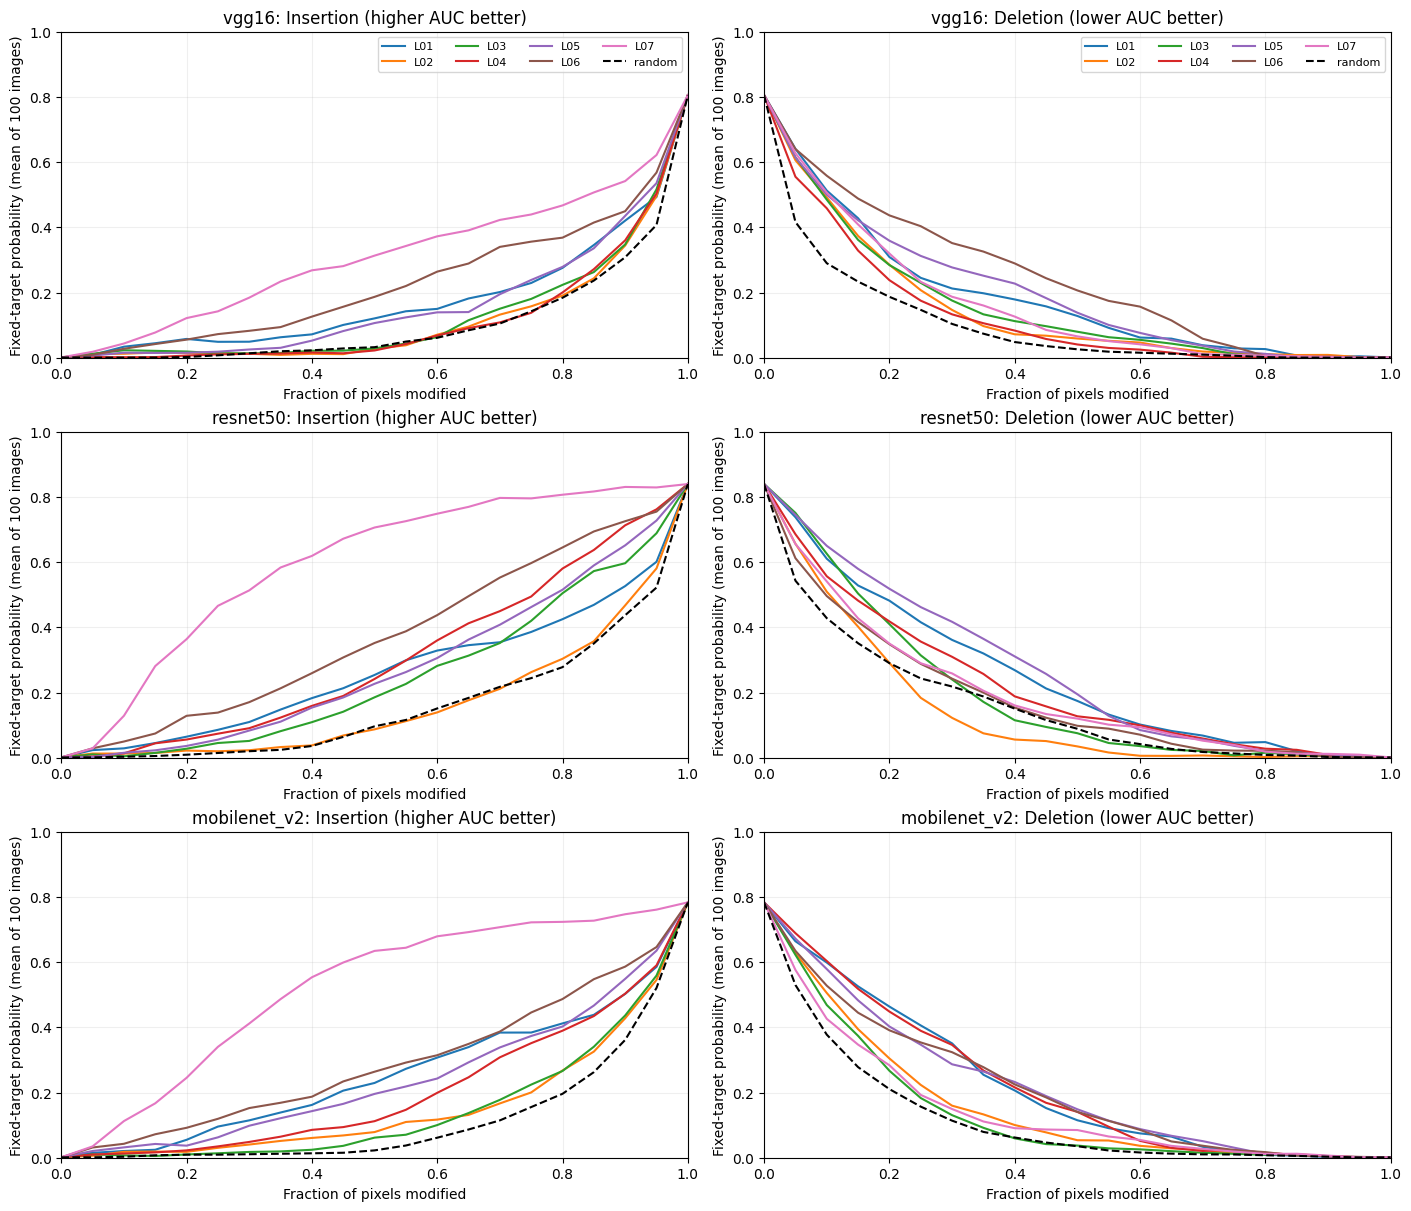

In [12]:
auc_rows=[]; curve_rows=[]; id_summary_rows=[]
bootstrap_indices=np.random.default_rng(SEED+30000).integers(0,ID_N,size=(ID_REPEATS,ID_N))
for name,arrays in id_data.items():
    aucs=auc_probability(arrays['curves'])
    assert aucs.shape==(ID_N,8,2)
    for method_index,method in enumerate(ID_METHODS):
        ins=aucs[:,method_index,0]; deletion=aucs[:,method_index,1]
        ins_gain=ins-aucs[:,7,0]; del_gain=aucs[:,7,1]-deletion
        ins_ci=np.quantile(ins_gain[bootstrap_indices].mean(1),[.025,.975])
        del_ci=np.quantile(del_gain[bootstrap_indices].mean(1),[.025,.975])
        id_summary_rows.append({'model':name,'method':method,'n':ID_N,
            'insertion_auc_mean':float(ins.mean()),'deletion_auc_mean':float(deletion.mean()),
            'insertion_gain_vs_random':float(ins_gain.mean()),'ins_gain_ci_low':float(ins_ci[0]),'ins_gain_ci_high':float(ins_ci[1]),
            'deletion_gain_vs_random':float(del_gain.mean()),'del_gain_ci_low':float(del_ci[0]),'del_gain_ci_high':float(del_ci[1]),
            'all_zero_maps':int(arrays['all_zero'][:,method_index].sum()) if method_index<7 else 0})
        for image_index,image_id in enumerate(ID_IMAGE_IDS):
            auc_rows.append({'model':name,'image_id':image_id,'target_class':int(arrays['targets'][image_index]),
                'method':method,'insertion_auc':float(ins[image_index]),'deletion_auc':float(deletion[image_index]),
                'insertion_gain_vs_random':float(ins_gain[image_index]),'deletion_gain_vs_random':float(del_gain[image_index])})
            for metric_index,metric in enumerate(['insertion','deletion']):
                for step,fraction in enumerate(ID_FRACTIONS):
                    curve_rows.append({'model':name,'image_id':image_id,'method':method,'metric':metric,
                        'fraction':float(fraction),'target_probability':float(arrays['curves'][image_index,method_index,metric_index,step])})
id_summary=pd.DataFrame(id_summary_rows)
id_summary.to_csv(OUT/'results'/'id_summary.csv',index=False)
pd.DataFrame(auc_rows).to_csv(OUT/'results'/'id_per_image_auc.csv',index=False)
pd.DataFrame(curve_rows).to_csv(OUT/'results'/'id_curves.csv',index=False)
execution_audit_rows=[]
for model_name in SPECS:
    audit=json.loads((ID_DIR/f'{model_name}_id.json').read_text(encoding='utf-8'))
    execution_audit_rows.append({'model':model_name,'original_run_seconds':audit['seconds'],
        'non_inplace_forward_max_error':audit['relu_forward_equivalence_max_error'],
        'backward_warning_count':len(audit['backward_warnings']),
        'all_zero_maps':audit['all_zero_maps'],'endpoint_checks':audit['endpoint_checks_passed']})
display(pd.DataFrame(execution_audit_rows))
print('VGG16 backward records a CUDA adaptive-average-pooling nondeterminism warning; see the stated warn-only protocol.')
display(id_summary.round(5))
fig,axes=plt.subplots(3,2,figsize=(14,12),constrained_layout=True)
colors=plt.cm.tab10(np.arange(7))
for row,(name,arrays) in enumerate(id_data.items()):
    for metric_index,metric in enumerate(['Insertion (higher AUC better)','Deletion (lower AUC better)']):
        ax=axes[row,metric_index]
        for k,method in enumerate(ID_METHODS):
            mean_curve=arrays['curves'][:,k,metric_index].mean(0)
            ax.plot(ID_FRACTIONS,mean_curve,label=method,color=colors[k] if k<7 else 'black',
                    linestyle='-' if k<7 else '--',linewidth=1.5)
        ax.set(title=f'{name}: {metric}',xlabel='Fraction of pixels modified',
               ylabel='Fixed-target probability (mean of 100 images)',xlim=(0,1),ylim=(0,1))
        ax.grid(alpha=.2)
        if row==0: ax.legend(ncol=4,fontsize=8)
fig.savefig(OUT/'figures'/'insertion_deletion_curves.png',dpi=170)
display(fig);plt.close(fig)


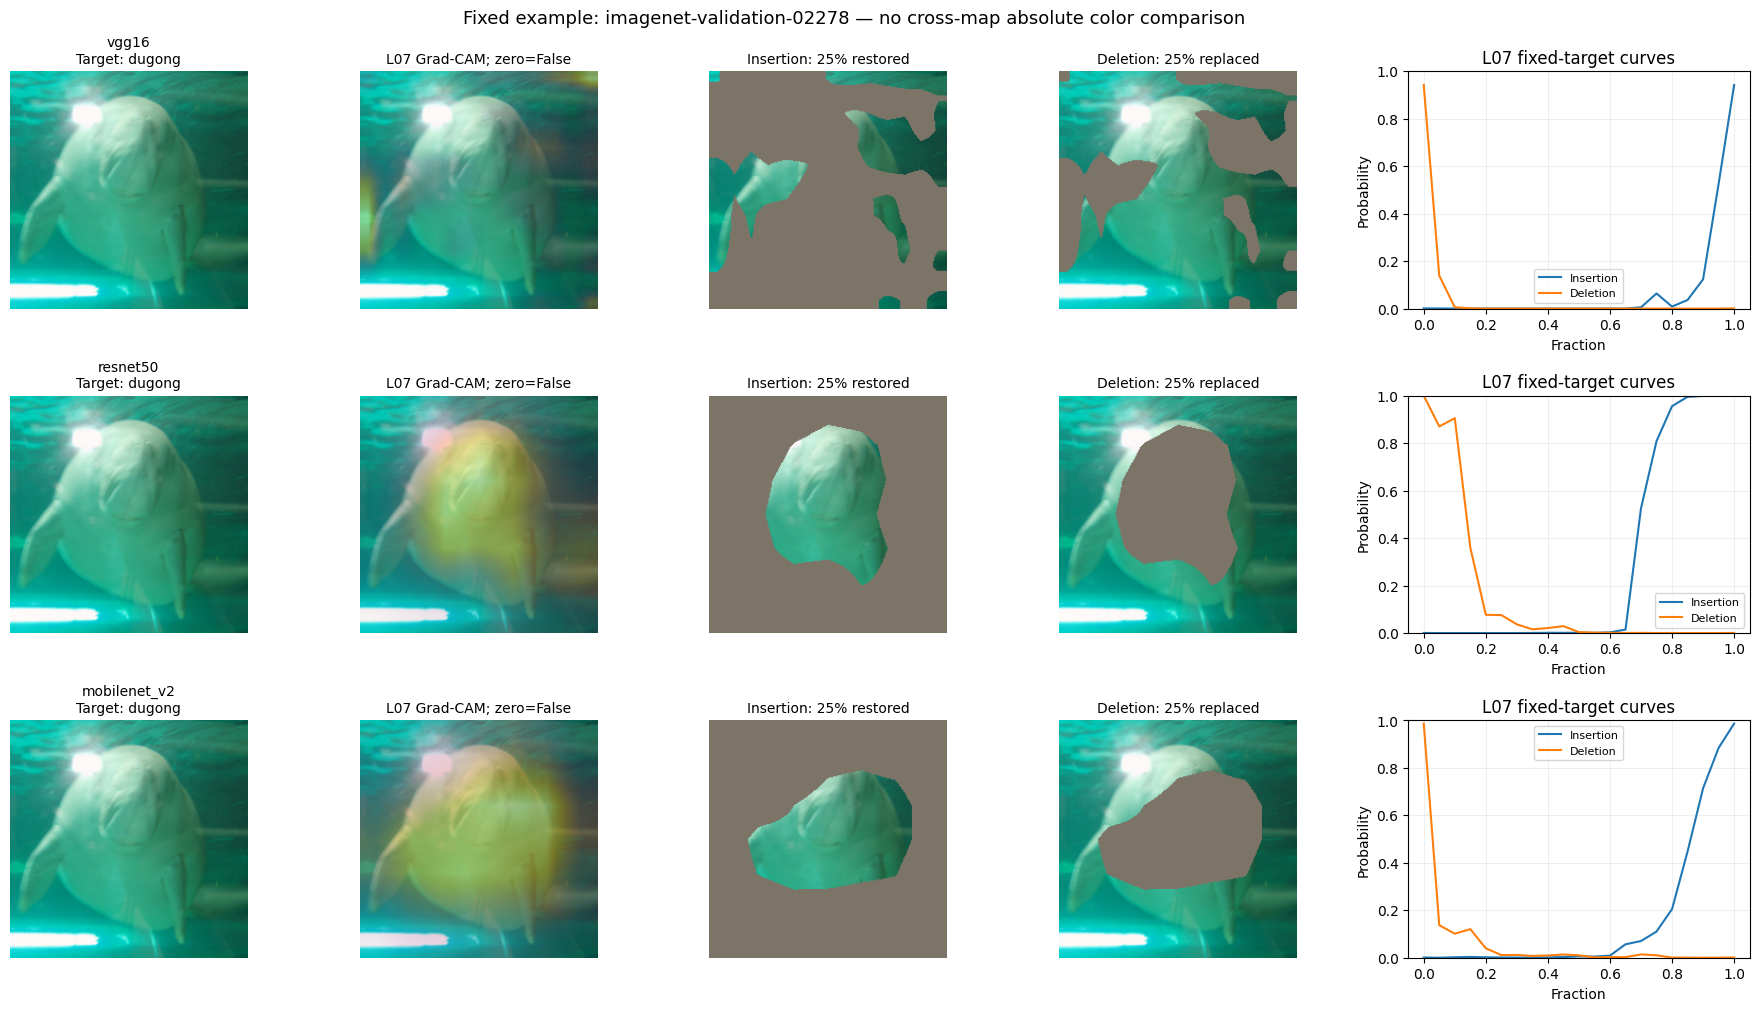

In [13]:
# One fixed, unfiltered example; no selection for visual appeal.
fig,axes=plt.subplots(3,5,figsize=(18,10),constrained_layout=True)
for row,(name,arrays) in enumerate(id_data.items()):
    x=dataset[0][0]
    rgb=(x.numpy().transpose(1,2,0)*np.array([.229,.224,.225])+np.array([.485,.456,.406])).clip(0,1)
    cam=arrays['cams'][0,6]
    colored=plt.cm.inferno(cam)[...,:3]
    overlay=rgb*(1-.5*cam[...,None])+colored*(.5*cam[...,None])
    order=ranked_pixels(cam,0)
    rank=np.empty(PIXELS,dtype=np.int64);rank[order]=np.arange(PIXELS)
    mask=(rank<ID_COUNTS[5]).reshape(224,224,1)
    baseline=np.broadcast_to(np.array([.485,.456,.406]),rgb.shape)
    views=[rgb,overlay,np.where(mask,rgb,baseline),np.where(mask,baseline,rgb)]
    target=int(arrays['targets'][0]); category=SPECS[name][1].meta['categories'][target]
    titles=[f'{name}\nTarget: {category}',f'L07 Grad-CAM; zero={bool(arrays["all_zero"][0,6])}',
            'Insertion: 25% restored','Deletion: 25% replaced']
    for ax,view,title in zip(axes[row,:4],views,titles): ax.imshow(view);ax.set_title(title,fontsize=10);ax.axis('off')
    ax=axes[row,4]
    ax.plot(ID_FRACTIONS,arrays['curves'][0,6,0],label='Insertion')
    ax.plot(ID_FRACTIONS,arrays['curves'][0,6,1],label='Deletion')
    ax.set(title='L07 fixed-target curves',xlabel='Fraction',ylabel='Probability',ylim=(0,1))
    ax.legend(fontsize=8);ax.grid(alpha=.2)
fig.suptitle(f'Fixed example: {ID_IMAGE_IDS[0]} — no cross-map absolute color comparison',fontsize=13)
fig.savefig(OUT/'figures'/'insertion_deletion_example.png',dpi=170)
display(fig);plt.close(fig)


## 11. 新增结果解读与CKA的关系

下面根据实际AUC和配对区间生成结论。跨21个层寻找“最佳”属于事后探索，不能当作预先指定、经多重比较校正的发现。
不同模型可能解释不同Top-1类别，所以模型间AUC的差别不等价于同一类别上的解释质量或分类能力差别。

CKA高的层可以有较差的Insertion/Deletion表现：前者比较跨图片的表示几何，后者检查特定类别的空间排序。
例如浅层GAP可能保留相似的全局颜色统计，但这种表示相似性本身不保证Grad-CAM能精确定位目标区域。


In [14]:
id_lines=['# Grad-CAM Insertion/Deletion：实际结果与解释',
    '固定ImageNet子集前100张、不按正确率筛选；每模型每图固定原始Top-1，七层共享目标。',
    '基线为ImageNet均值颜色；21个采样点，概率AUC；Insertion高为好，Deletion低为好。']
all_layers=id_summary[id_summary['method']!='random']
id_lines.extend(['\n## 综合发现',
    f"21个模型—层组合中，{int((all_layers.ins_gain_ci_low>0).sum())}个Insertion改进区间完全高于0；Deletion对应数量为{int((all_layers.del_gain_ci_low>0).sum())}，另有{int((all_layers.del_gain_ci_high<0).sum())}个Deletion改进区间完全低于0。所有区间均为未经多重比较校正的探索性区间。",
    '三种模型的L07均取得各自最高Insertion AUC，但没有层在Deletion上获得完全为正的改进区间。因此只能说部分空间排序有助于分数恢复，不能据此宣称其在两种扰动评估下都可靠。',
    '随机散点遮挡可能比连续区域遮挡更易破坏纹理或使输入偏离自然图像分布；这是一种解释假设，尚未用其他基线或块状遮挡验证。'])
for name in SPECS:
    table=id_summary[(id_summary['model']==name)&(id_summary['method']!='random')]
    random_row=id_summary[(id_summary['model']==name)&(id_summary['method']=='random')].iloc[0]
    best_ins=table.loc[table['insertion_auc_mean'].idxmax()]
    best_del=table.loc[table['deletion_auc_mean'].idxmin()]
    wins_ins=int((table['ins_gain_ci_low']>0).sum())
    wins_del=int((table['del_gain_ci_low']>0).sum())
    id_lines.extend([f'\n## {name}',
        f'随机排序平均Insertion／Deletion AUC：{random_row.insertion_auc_mean:.4f}／{random_row.deletion_auc_mean:.4f}。',
        f'本样本中Insertion最高为{best_ins.method}，AUC={best_ins.insertion_auc_mean:.4f}；Deletion最低为{best_del.method}，AUC={best_del.deletion_auc_mean:.4f}。',
        f'在Insertion／Deletion上，分别有{wins_ins}／{wins_del}个层的配对改进95%区间完全位于0以上；这是未经多重比较校正的探索性描述。',
        f'Deletion最优采样层相对随机的平均改进为{best_del.deletion_gain_vs_random:.4f}，95%区间[{best_del.del_gain_ci_low:.4f}, {best_del.del_gain_ci_high:.4f}]；正值才表示优于随机。',
        f'七层中共{int(table.all_zero_maps.sum())}张全零CAM；它们保留在评估中，并已检查与随机排序曲线一致。'])
id_lines.extend(['\n## 怎样解释，而不是过度解读',
    '1. CAM相对随机排序的正向改进，表示其在本协议下更快恢复／破坏该固定目标的分数；不等于分类准确率提高。',
    '2. 若Insertion和Deletion选择不同层，应分别报告，不能只挑对自己有利的一个指标。',
    '3. 固定目标、原始／基线端点、像素计数、AUC方向、非inplace前向等价及全零图行为均在代码中校验。',
    '4. 只用均值颜色基线、100个类别各一张、20个区间及一个随机排序／图；未覆盖其他基线、步长与所有可能随机排序。bootstrap区间不覆盖全部这些不确定性。',
    '5. 遮挡图片可能偏离自然图像分布；概率受模型校准影响；不同模型Top-1可能不同，所以不将这些AUC用作模型准确率排行榜。',
    '6. CKA与扰动评估互补：表示相似并不保证解释图相同或扰动评估一样好。本实验不把两者的相关性当作已验证因果关系。'])
id_text='\n\n'.join(id_lines)
display(Markdown(id_text))
(OUT/'insertion_deletion_summary.md').write_text(id_text,encoding='utf-8')
id_config={'protocol':ID_PROTOCOL,'complete':True,'n_models':3,'cam_combinations':2100,
    'random_controls':300,'summary_sha256':sha256_file(OUT/'results'/'id_summary.csv'),
    'per_image_auc_sha256':sha256_file(OUT/'results'/'id_per_image_auc.csv'),
    'curves_sha256':sha256_file(OUT/'results'/'id_curves.csv'),
    'cache_sha256':{name:sha256_file(ID_DIR/f'{name}_id.npz') for name in SPECS}}
(ID_DIR/'experiment_config.json').write_text(json.dumps(id_config,indent=2),encoding='utf-8')
config['insertion_deletion']=id_config
(OUT/'experiment_config.json').write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8')
print('Completed: CKA + 2100 Grad-CAM I/D evaluations + 300 random controls.')


# Grad-CAM Insertion/Deletion：实际结果与解释

固定ImageNet子集前100张、不按正确率筛选；每模型每图固定原始Top-1，七层共享目标。

基线为ImageNet均值颜色；21个采样点，概率AUC；Insertion高为好，Deletion低为好。


## 综合发现

21个模型—层组合中，17个Insertion改进区间完全高于0；Deletion对应数量为0，另有16个Deletion改进区间完全低于0。所有区间均为未经多重比较校正的探索性区间。

三种模型的L07均取得各自最高Insertion AUC，但没有层在Deletion上获得完全为正的改进区间。因此只能说部分空间排序有助于分数恢复，不能据此宣称其在两种扰动评估下都可靠。

随机散点遮挡可能比连续区域遮挡更易破坏纹理或使输入偏离自然图像分布；这是一种解释假设，尚未用其他基线或块状遮挡验证。


## vgg16

随机排序平均Insertion／Deletion AUC：0.1054／0.1014。

本样本中Insertion最高为L07，AUC=0.3096；Deletion最低为L04，AUC=0.1327。

在Insertion／Deletion上，分别有4／0个层的配对改进95%区间完全位于0以上；这是未经多重比较校正的探索性描述。

Deletion最优采样层相对随机的平均改进为-0.0313，95%区间[-0.0555, -0.0072]；正值才表示优于随机。

七层中共2张全零CAM；它们保留在评估中，并已检查与随机排序曲线一致。


## resnet50

随机排序平均Insertion／Deletion AUC：0.1596／0.1605。

本样本中Insertion最高为L07，AUC=0.5950；Deletion最低为L02，AUC=0.1426。

在Insertion／Deletion上，分别有6／0个层的配对改进95%区间完全位于0以上；这是未经多重比较校正的探索性描述。

Deletion最优采样层相对随机的平均改进为0.0179，95%区间[-0.0097, 0.0441]；正值才表示优于随机。

七层中共0张全零CAM；它们保留在评估中，并已检查与随机排序曲线一致。


## mobilenet_v2

随机排序平均Insertion／Deletion AUC：0.1146／0.1185。

本样本中Insertion最高为L07，AUC=0.5189；Deletion最低为L03，AUC=0.1397。

在Insertion／Deletion上，分别有7／0个层的配对改进95%区间完全位于0以上；这是未经多重比较校正的探索性描述。

Deletion最优采样层相对随机的平均改进为-0.0212，95%区间[-0.0468, 0.0034]；正值才表示优于随机。

七层中共6张全零CAM；它们保留在评估中，并已检查与随机排序曲线一致。


## 怎样解释，而不是过度解读

1. CAM相对随机排序的正向改进，表示其在本协议下更快恢复／破坏该固定目标的分数；不等于分类准确率提高。

2. 若Insertion和Deletion选择不同层，应分别报告，不能只挑对自己有利的一个指标。

3. 固定目标、原始／基线端点、像素计数、AUC方向、非inplace前向等价及全零图行为均在代码中校验。

4. 只用均值颜色基线、100个类别各一张、20个区间及一个随机排序／图；未覆盖其他基线、步长与所有可能随机排序。bootstrap区间不覆盖全部这些不确定性。

5. 遮挡图片可能偏离自然图像分布；概率受模型校准影响；不同模型Top-1可能不同，所以不将这些AUC用作模型准确率排行榜。

6. CKA与扰动评估互补：表示相似并不保证解释图相同或扰动评估一样好。本实验不把两者的相关性当作已验证因果关系。

Completed: CKA + 2100 Grad-CAM I/D evaluations + 300 random controls.


## 12. 实验记录、交付与术语回顾

记录已知尝试：最初系统默认Python 3.7没有torch；定位到5070ti后验证CUDA可用。最初考虑CIFAR10替代，团队明确后撤销；本notebook只使用ImageNet。
官方权重下载曾遇到网络限制／中断，应以实际文件哈希和成功前向为准，部分文件不算完成。更换环境或失败运行时应保留简短记录。

术语回顾：**缓存**是保存以便复用的数值；**manifest**是来源与配置清单；**seed**固定随机过程起点；
**checkpoint**是训练存档，通常不是图片；**logit**是类别原始分数；**probe**是额外训练的分类读出头；
**Grad-CAM**解释预测的空间响应；**activation maximization**优化人工输入激发通道；**CKA**比较样本关系。
只用自己的CKA数值，不把合成图、Grad-CAM颜色或softmax概率当作卷积特征。

交付核心就是本notebook（包含代码、图、表与解释）。输出CSV、图和配置是便于团队复用的附属文件。
团队的两个meme、演示和最终提交另行分工；本模块不替团队虚构这部分交付。

参考：[CKA论文](https://proceedings.mlr.press/v97/kornblith19a.html)、
[作者实现](https://github.com/google-research/google-research/blob/master/representation_similarity/Demo.ipynb)、
[ImageNet数据卡及访问条件](https://huggingface.co/datasets/ILSVRC/imagenet-1k)、
[VGG16](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.vgg16.html)、
[ResNet50](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet50.html)、
[MobileNetV2](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.mobilenet_v2.html)。
本地依据：`背景资料/Assignment2-2026A.ipynb`、Lecture5b、Lecture6a、`搭档已完成/`的模型及两图实验。

新增参考：[Grad-CAM](https://arxiv.org/abs/1610.02391)、[RISE扰动评估](https://arxiv.org/abs/1806.07421)。Insertion/Deletion基线与AUC方向详见新增章节。
